# Hénon–Heiles Computational Physics Project

This notebook contains the numerical implementation and experiments for the Hénon–Heiles escape problem. **Start with the [README](README.md)** for the project overview, governing equations, numerical methods, main results, limitations, and a guide to the notebook sections. The section numbers below correspond to the README's notebook guide.

Run the cells from top to bottom. The notebook uses NumPy, Matplotlib, and SciPy.

## 1. Equations of motion and energy

**What this section does:** Defines the potential-derived accelerations and computes kinetic, potential, and total energy. The force is obtained from $\mathbf a=-\nabla V$.

**README:** [Physical model](README.md#physical-model).

In [33]:
import numpy as np

def acceleration(x, y):
    ax = -x - 2*x*y
    ay = -y - x**2 + y**2
    return np.array([ax, ay])

def total_energy(x, y, vx, vy):
    V = 0.5*(x**2 + y**2) + x**2*y - y**3/3
    K = 0.5*(vx**2 + vy**2)
    return K + V


## 2. Escape geometry and channel classification

**What this section does:** Defines radius, radial velocity, and polar angle. An escape is an outward crossing of the chosen radius; the angle at that crossing is then assigned to one of the three approximate channel sectors.

**README:** [Escape definition](README.md#escape-definition).

In [34]:
def r(x, y):
    return np.sqrt(x**2 + y**2)


def vr(x, y, vx, vy):
    return (x*vx + y*vy) / r(x, y)


def angle(x, y):
    return np.degrees(np.arctan2(y, x)) % 360


def classify_channel(phi):
    if 60 <= phi <= 120:
        return "Upper"
    if 180 <= phi <= 240:
        return "Lower-left"
    if 300 <= phi < 360:
        return "Lower-right"
    return None


## 3. Time grid and Velocity Verlet integrator

**What this section does:** Creates the uniform time grid and advances position and velocity using Velocity Verlet. Integration stops when the trajectory crosses the escape radius outwards; escape detection does not depend on whether the channel can be classified.

**README:** [Numerical method](README.md#numerical-method).

In [35]:
def time_array(T, N):
    dt = T/N
    t = np.linspace(0, T, N+1)
    return t, dt

def velocity_verlet(x, y, vx, vy, dt, R):

    last = 0
    escape_info = None

    for i in range(len(x)-1):

        ax, ay = acceleration(x[i], y[i])
        x[i+1] = x[i] + dt*vx[i] + 0.5*dt**2*ax
        y[i+1] = y[i] + dt*vy[i] + 0.5*dt**2*ay
        ax_new, ay_new = acceleration(x[i+1], y[i+1])
        vx[i+1] = vx[i] + 0.5*dt*(ax + ax_new)
        vy[i+1] = vy[i] + 0.5*dt*(ay + ay_new)

        last = i+1

        if (r(x[i+1], y[i+1]) > R and vr(x[i+1], y[i+1], vx[i+1], vy[i+1]) > 0):

            phi = angle(x[i+1], y[i+1])
            channel = classify_channel(phi)

            if channel is None:
                channel = "Unclassified"

            escape_info = {
                "time": (i+1)*dt,
                "angle": phi,
                "channel": channel,
                "position": (x[i+1], y[i+1])
            }
            break

    return last, escape_info

## 4. Initial conditions and simulation output

**What this section does:** Launches each particle from the origin with speed $\sqrt{2E}$ in the requested direction. It trims the trajectory arrays at the last computed point and returns the trajectory, energy history, and escape information.

**README:** [Initial conditions and escape definition](README.md#escape-definition).

In [36]:
def final_arrays(T, N, E, theta, R):

    t, dt = time_array(T, N)

    x = np.zeros(N+1)
    y = np.zeros(N+1)
    vx = np.zeros(N+1)
    vy = np.zeros(N+1)

    theta = np.radians(theta)

    x[0] = 0
    y[0] = 0
    vx[0] = np.sqrt(2*E)*np.cos(theta)
    vy[0] = np.sqrt(2*E)*np.sin(theta)

    last, escape_info = velocity_verlet(x, y, vx, vy, dt, R)

    t = t[:last+1]
    x = x[:last+1]
    y = y[:last+1]
    vx = vx[:last+1]
    vy = vy[:last+1]

    energy = total_energy(x, y, vx, vy)

    return {"t": t, "x": x, "y": y, "vx": vx, "vy": vy, "energy": energy, "escaped": escape_info is not None, "escape": escape_info}

## 5. Plotting and error-analysis functions

**What this section does:** Defines reusable functions for energy error, trajectory plots, and potential-energy contours. These helpers are used by the later simulation sections.

**README:** [Numerical method](README.md#numerical-method).

In [37]:
import matplotlib.pyplot as plt

def energy_error(energy):
    return energy - energy[0], np.max(np.abs(energy - energy[0]))

def energy_error_plot(energy_error, t):
    plt.plot(t, energy_error)
    plt.axhline(0, color='red', linestyle='--')
    plt.xlabel("Time")
    plt.ylabel("Energy Error")
    plt.title("Velocity Verlet: Energy Conservation")
    plt.grid()
    plt.show()

def trajectory_plot(x, y):
    plt.plot(x, y)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Trajectory of the Henon-Heiles System")
    plt.grid()
    plt.axis('equal')
    plt.show()

def heatmap_and_trajectory(x, y, E):
    x_grid = np.linspace(-1.2, 1.2, 500)
    y_grid = np.linspace(-1.2, 1.2, 500)

    X, Y = np.meshgrid(x_grid, y_grid)

    V_grid = 0.5*(X**2 + Y**2) + X**2*Y - Y**3/3

    plt.figure(figsize=(9, 8))

    # Potential energy heatmap
    heatmap = plt.contourf(X, Y, V_grid, levels=np.linspace(-0.05, 0.5, 70), cmap='viridis', extend='both')

    plt.colorbar(heatmap, label='Potential Energy')

    # Energy boundary
    contour = plt.contour(X, Y, V_grid, levels=[E], colors='red', linewidths=2)
    plt.clabel(contour, fmt={E: f'V = E = {E:.3f}'})

    outside = np.where((np.abs(x) > 1.2) | (np.abs(y) > 1.2))[0]
    end = outside[0] if len(outside) > 0 else len(x)

    # Particle trajectory
    plt.plot(x[:end], y[:end], color='white', linewidth=1.2, label='Particle trajectory')

    plt.scatter(x[0], y[0], color='cyan', s=60, label='Starting position')

    # Saddle points
    saddles_x = [0, np.sqrt(3)/2, -np.sqrt(3)/2]
    saddles_y = [1, -0.5, -0.5]

    plt.scatter(saddles_x, saddles_y, color='red', marker='x', s=80, label='Saddle points')

    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Hénon–Heiles Potential and Particle Trajectory')

    plt.xlim(-1.2, 1.2)
    plt.ylim(-1.2, 1.2)

    plt.axis('equal')
    plt.legend()
    plt.show()

def plots(x, y, energy, t, E):
    error, max_error = energy_error(energy)
    energy_error_plot(error, t)
    print("Maximum absolute energy error:", max_error)
    heatmap_and_trajectory(x, y, E)


## 6. Confined trajectory and energy convergence

**What this section does:** Simulates a below-threshold launch and compares the maximum energy error for $N=5{,}000$, $10{,}000$, and $20{,}000$. Halving the timestep should reduce the global error by approximately a factor of four for a second-order method.

**README:** [Numerical validation](README.md#numerical-validation).

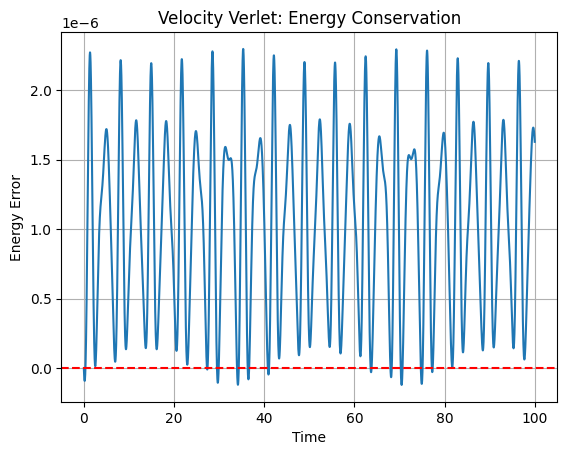

Maximum absolute energy error: 2.297483627802799e-06


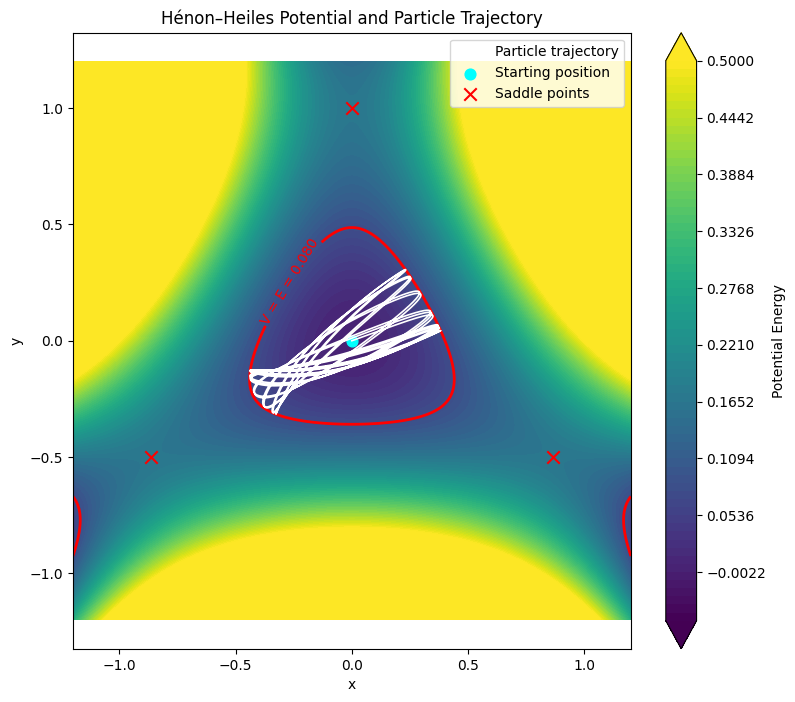

In [38]:
not_escaped_sim1 = final_arrays(100, 10000, 0.08, 20, 2.5)
plots(not_escaped_sim1["x"], not_escaped_sim1["y"], not_escaped_sim1["energy"], not_escaped_sim1["t"], 0.08)

In [39]:
not_escaped_sim2 = final_arrays(100, 5000, 0.08, 20, 2.5)
not_escaped_sim3 = final_arrays(100, 20000, 0.08, 20, 2.5)

In [40]:
max_error_5000 = energy_error(not_escaped_sim2["energy"])[1]
max_error_10000 = energy_error(not_escaped_sim1["energy"])[1]
max_error_20000 = energy_error(not_escaped_sim3["energy"])[1]

print("Individual maximum absolute energy errors:")
print("N=5000:", max_error_5000)
print("N=10000:", max_error_10000)
print("N=20000:", max_error_20000)

ratio1 = max_error_5000 / max_error_10000
ratio2 = max_error_10000 / max_error_20000

print("Ratios of maximum absolute energy error:")
print("Ratio (N=5000 / N=10000):", ratio1)
print("Ratio (N=10000 / N=20000):", ratio2)

Individual maximum absolute energy errors:
N=5000: 9.190789078142303e-06
N=10000: 2.297483627802799e-06
N=20000: 5.743575351990771e-07
Ratios of maximum absolute energy error:
Ratio (N=5000 / N=10000): 4.000371957789281
Ratio (N=10000 / N=20000): 4.000093124932142


## 7. Escape along the three symmetry directions

**What this section does:** Simulates launches at $90^\circ$, $210^\circ$, and $330^\circ$, the three symmetry directions, then checks energy conservation for the upper-channel trajectory at finer timesteps.

**README:** [Numerical validation](README.md#numerical-validation).

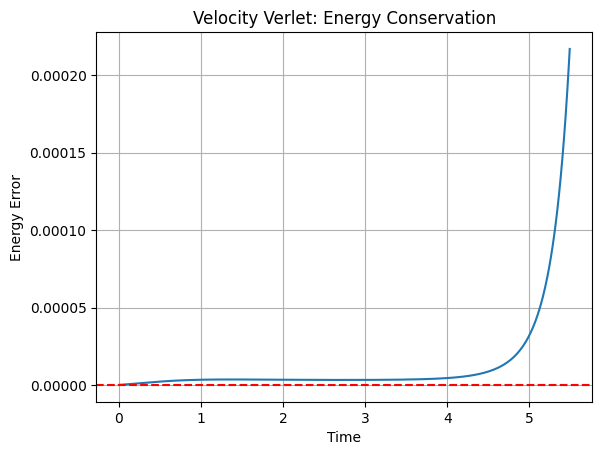

Maximum absolute energy error: 0.00021699633557464848


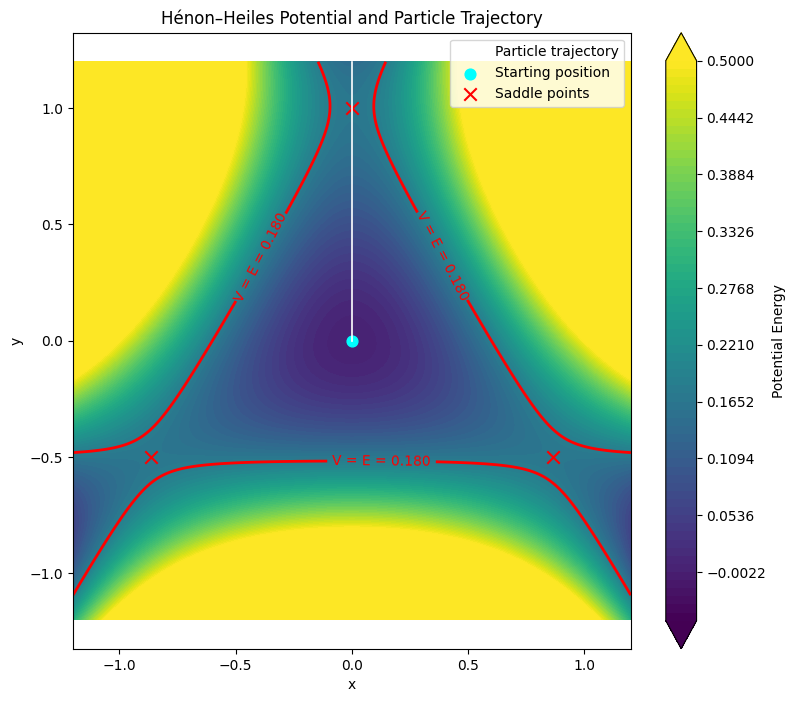

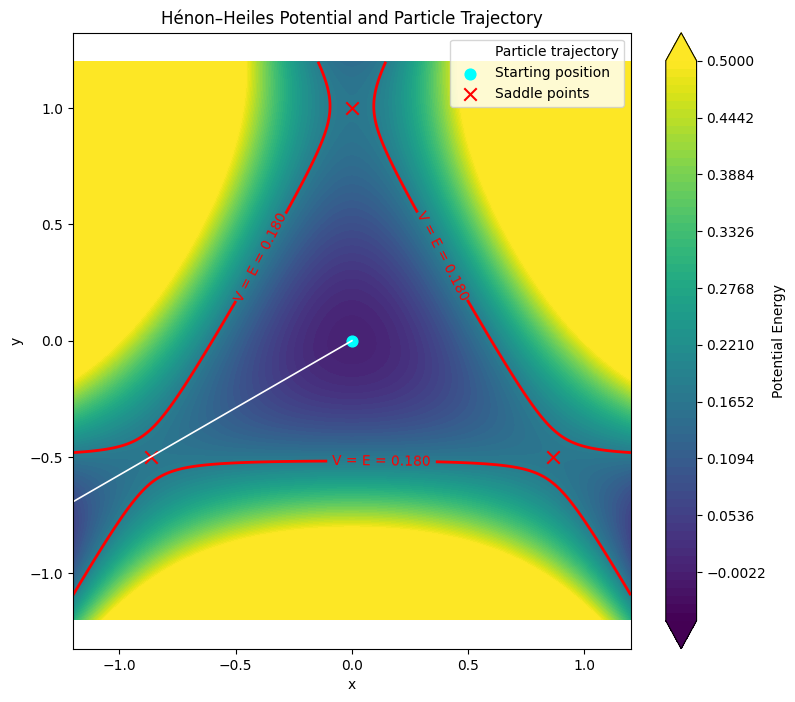

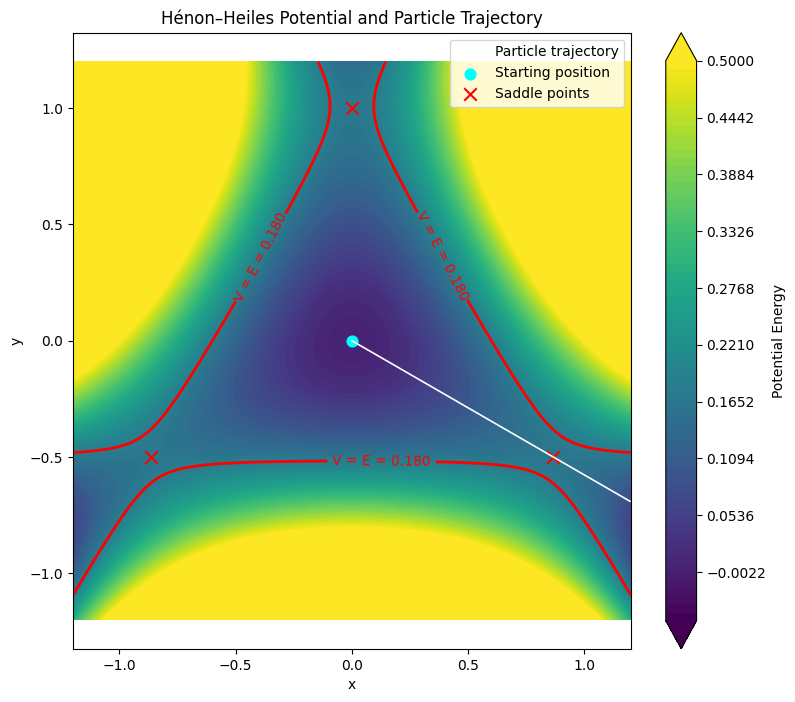

In [41]:
escaped_sim1 = final_arrays(100, 10000, 0.18, 90, 2.5)
sim_upper = escaped_sim1
sim_left = final_arrays(100, 10000, 0.18, 210, 2.5)
sim_right = final_arrays(100, 10000, 0.18, 330, 2.5)
plots(escaped_sim1["x"], escaped_sim1["y"], escaped_sim1["energy"], escaped_sim1["t"], 0.18)
heatmap_and_trajectory(sim_left["x"], sim_left["y"], 0.18)
heatmap_and_trajectory(sim_right["x"], sim_right["y"], 0.18)

In [42]:
escaped_sim2 = final_arrays(100, 20000, 0.18, 90, 2.5)
escaped_sim3 = final_arrays(100, 40000, 0.18, 90, 2.5)

In [43]:
max_error1 = energy_error(escaped_sim1["energy"])[1]
max_error2 = energy_error(escaped_sim2["energy"])[1]
max_error3 = energy_error(escaped_sim3["energy"])[1]
print("Individual maximum absolute energy errors:")
print("N=10000:", max_error1)
print("N=20000:", max_error2)
print("N=40000:", max_error3)

ratio1 = max_error1 / max_error2
ratio2 = max_error2 / max_error3

print("Ratios of maximum absolute energy error:")
print("Ratio (N=10000 / N=20000):", ratio1)
print("Ratio (N=20000 / N=40000):", ratio2)

Individual maximum absolute energy errors:
N=10000: 0.00021699633557464848
N=20000: 5.421318328985292e-05
N=40000: 1.3398811523124277e-05
Ratios of maximum absolute energy error:
Ratio (N=10000 / N=20000): 4.002648846766091
Ratio (N=20000 / N=40000): 4.046118806603806


## 8. Poincaré sections

**What this section does:** Uses the surface $x=0$ with $v_x>0$ and records successive crossings in the $(y,v_y)$ plane. Fifteen starting points are chosen with $v_y=0$; their positive $v_x$ values are calculated from the fixed-energy condition. The initial crossing at $t=0$ is discarded, and each trajectory is followed only until the escape event or the end of the section run.

The three requested energies are supplemented with $E=0.18$ as an above-threshold comparison.

**README:** [Poincaré sections](README.md#poincare-sections).

**Solver support for this section:** Imports SciPy and defines the first-order equations of motion and outward escape event used by the Poincaré-section calculation. The same helpers are reused later for independent solver validation.

In [44]:
from scipy.integrate import solve_ivp

def henon_heiles_ode(t, state):
    x, y, vx, vy = state
    ax, ay = acceleration(x, y)
    return [vx, vy, ax, ay]

def make_escape_event(R):
    def escape_event(t, state):
        return np.hypot(state[0], state[1]) - R
    escape_event.terminal = True
    escape_event.direction = 1
    return escape_event

In [45]:
def poincare_section(T, E, R, initial_y_values):
    section_y = []
    section_vy = []
    escaped = 0

    def crossing(t, state):
        return state[0]

    crossing.direction = 1
    crossing.terminal = False

    for y0 in initial_y_values:
        vx_squared = 2*(E - (0.5*y0**2 - y0**3/3))
        if vx_squared <= 0:
            continue

        initial_state = [0, y0, np.sqrt(vx_squared), 0]
        solution = solve_ivp(henon_heiles_ode, (0, T), initial_state,
                             method="DOP853",
                             events=[crossing, make_escape_event(R)],
                             rtol=1e-9, atol=1e-11)

        points = solution.y_events[0]
        times = solution.t_events[0]
        points = points[(times > 1e-8) & (points[:, 2] > 0)]

        section_y.extend(points[:, 1])
        section_vy.extend(points[:, 3])
        if len(solution.t_events[1]) > 0:
            escaped += 1

    return {"y": np.array(section_y), "vy": np.array(section_vy),
            "escaped": escaped}

poincare_energies = [1/12, 1/8, 1/6, 0.18]
poincare_initial_y = np.linspace(-0.3, 0.45, 15)
poincare_results = {}

for energy_value in poincare_energies:
    data = poincare_section(150, energy_value, 2.5, poincare_initial_y)
    poincare_results[energy_value] = data
    print("Energy:", energy_value, "| Section points:", len(data["y"]),
          "| Escaped trajectories:", data["escaped"])

Energy: 0.08333333333333333 | Section points: 350 | Escaped trajectories: 0
Energy: 0.125 | Section points: 347 | Escaped trajectories: 0
Energy: 0.16666666666666666 | Section points: 342 | Escaped trajectories: 0
Energy: 0.18 | Section points: 267 | Escaped trajectories: 5


### Poincaré-section plots

**What this plot shows:** Each panel combines the successive $(y,v_y)$ crossings from the 15 selected initial conditions at one energy. The points are plotted together rather than colour-coded by starting trajectory. At $E=0.18$, some trajectories escape before the end of the section run and therefore contribute fewer crossings.

**README:** [Poincaré sections](README.md#poincare-sections).

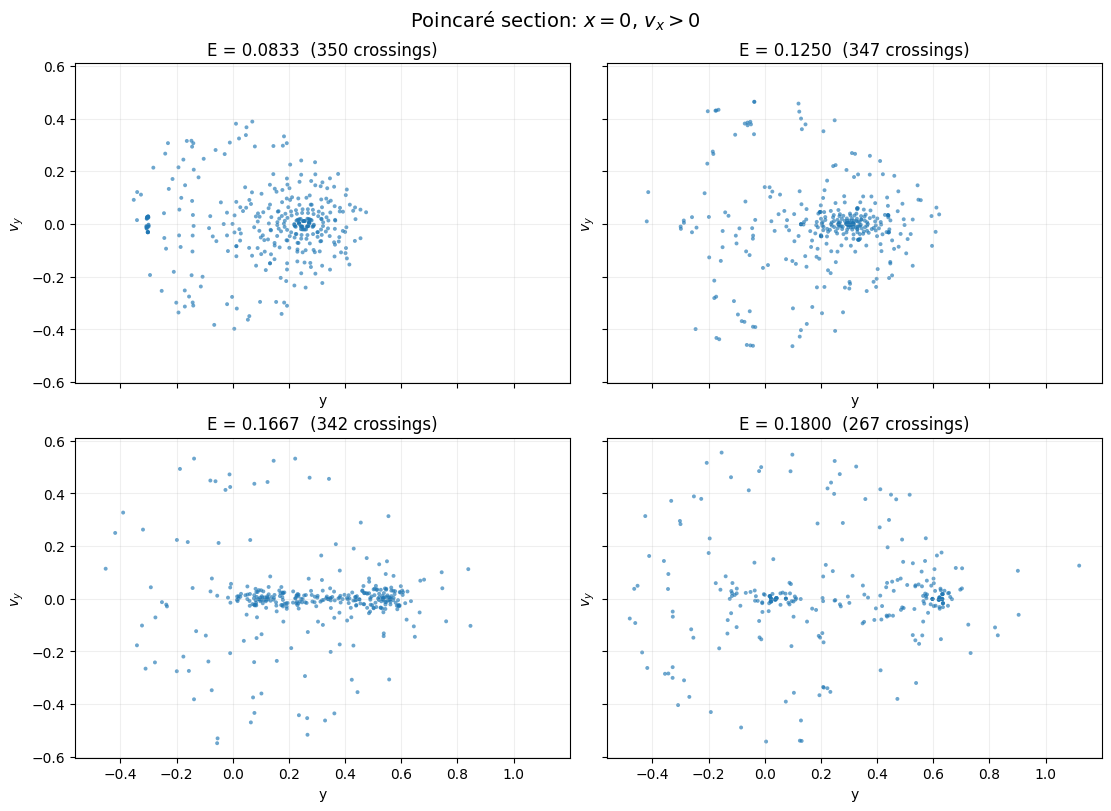

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), sharex=True, sharey=True, constrained_layout=True)

for ax, energy_value in zip(axes.flat, poincare_energies):
    section_data = poincare_results[energy_value]
    ax.scatter(section_data["y"], section_data["vy"], s=8, alpha=0.65, edgecolors="none")
    ax.set_title(f"E = {energy_value:.4f}  ({len(section_data['y'])} crossings)")
    ax.set_xlabel("y")
    ax.set_ylabel(r"$v_y$")
    ax.grid(alpha=0.2)

fig.suptitle(r"Poincaré section: $x=0$, $v_x>0$", fontsize=14)
plt.show()


**How to read these sections:** Regular trajectories often trace smooth invariant curves in a Poincaré section, while chaotic trajectories can fill broader, less regular regions. These finite ensembles and finite integration times are qualitative diagnostics; they do not prove that every orbit at a given energy is regular or chaotic.

**README:** [Poincaré sections and limitations](README.md#poincare-sections).

## 9. Full angular escape sweep

**What this section does:** Samples initial angles over the full $0^\circ$–$360^\circ$ range at fixed energy and records each trajectory's escape outcome and escape time. Non-escape means only that the trajectory did not cross the escape radius during the chosen time horizon.

**README:** [Escape-basin investigation](README.md#escape-basin-investigation).

In [47]:
def escape_statistics(T, N, E, R, lim1, lim2, step):
    info = []
    angles = np.arange(lim1, lim2, step)
    for theta in angles:
        trial = final_arrays(T, N, E, theta, R)
        info.append({
            "theta": float(theta),
            "escaped": trial["escaped"],
            "escape_time": trial["escape"]["time"] if trial["escaped"] else None,
            "escape_angle": trial["escape"]["angle"] if trial["escaped"] else None,
            "channel": trial["escape"]["channel"] if trial["escaped"] else None
        })

    return info

T = 100
N = 20000
E = 0.18
R = 2.5
lim1 = 0
lim2 = 360
step = 1

info = escape_statistics(T, N, E, R, lim1, lim2, step)
escaped_entries = [entry for entry in info if entry["escaped"]]
not_escaped_entries = [entry for entry in info if not entry["escaped"]]

print("Number of escaped particles:", len(escaped_entries))
print("Number of non-escaped particles:", len(not_escaped_entries))

Number of escaped particles: 228
Number of non-escaped particles: 132


## 10. Escape channels and escape times

**What this section does:** Plots the channel reached and escape time against initial angle, counts the channel populations, and summarizes the escape-time distribution for the full angular sweep.

**README:** [Escape-basin investigation](README.md#escape-basin-investigation).

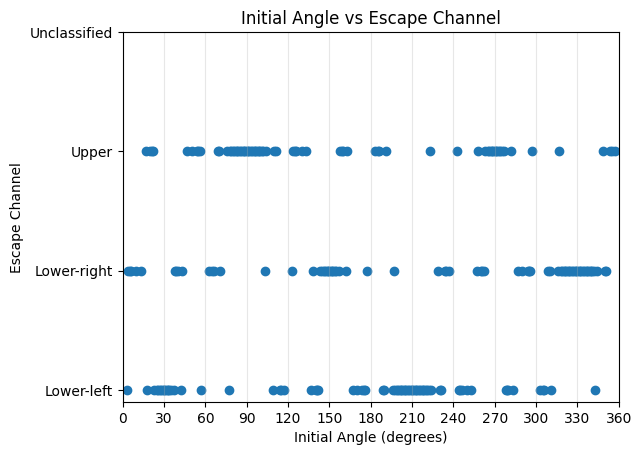

Lower-left: 76
Lower-right: 76
Upper: 76
Unclassified: 0


In [48]:
channel_codes = {"Lower-left": 0, "Lower-right": 1, "Upper": 2, "Unclassified": 3}
angles = [entry["theta"] for entry in escaped_entries]
channels = [channel_codes.get(entry["channel"], 3) for entry in escaped_entries]

plt.scatter(angles, channels)
plt.yticks([0, 1, 2, 3], ["Lower-left", "Lower-right", "Upper", "Unclassified"])
plt.xlabel("Initial Angle (degrees)")
plt.ylabel("Escape Channel")
plt.title("Initial Angle vs Escape Channel")
plt.xlim(0, 360)
plt.xticks(np.arange(0, 361, 30))
plt.grid(axis='x', alpha=0.3)
plt.show()

num_particles = [channels.count(code) for code in channel_codes.values()]
for channel, count in zip(channel_codes, num_particles):
    print(f"{channel}: {count}")


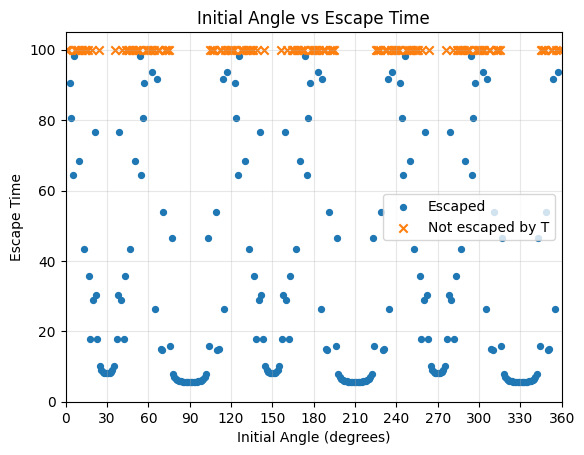

Mean Escape Time: 29.85868421052632
Median Escape Time: 14.9
Minimum Escape Time: 5.49
Maximum Escape Time: 98.11500000000001
Initial angle(s) corresponding to maximum escape time: [6.0, 54.0, 126.0, 174.0, 246.0, 294.0]


In [49]:
#Plot of initial angle vs escape time for escaping particles
plt.scatter([entry["theta"] for entry in escaped_entries], [entry["escape_time"] for entry in escaped_entries], s=18, label="Escaped")

# Mark trajectories that did not escape within T
plt.scatter([entry["theta"] for entry in not_escaped_entries], [T] * len(not_escaped_entries), marker='x', label="Not escaped by T")

plt.xlabel("Initial Angle (degrees)")
plt.ylabel("Escape Time")
plt.title("Initial Angle vs Escape Time")
plt.xlim(0, 360)
plt.ylim(0, T * 1.05)
plt.xticks(np.arange(0, 361, 30))
plt.grid(alpha=0.3)
plt.legend()
plt.show()

times = [entry["escape_time"] for entry in escaped_entries]
escape_times = np.array(times)

print("Mean Escape Time:", np.mean(escape_times))
print("Median Escape Time:", np.median(escape_times))
print("Minimum Escape Time:", np.min(escape_times))
print("Maximum Escape Time:", np.max(escape_times))

max_escape_time = np.max(escape_times)
max_time_angles = [entry["theta"] for entry in escaped_entries if entry["escape_time"] == max_escape_time]
print("Initial angle(s) corresponding to maximum escape time:", max_time_angles)

## 11. Transition detection

**What this section does:** Counts adjacent sampled angles whose outcomes differ. The complete circular sweep includes the 360°→0° neighbour; restricted angular intervals do not wrap around.

**README:** [Escape-basin investigation](README.md#escape-basin-investigation).

In [50]:
def return_transitions(info, circular=True):

    transitions = []

    if circular:
        n = len(info)
    else:
        n = len(info) - 1

    for i in range(n):

        current = info[i]
        next_entry = info[(i+1) % len(info)]

        outcome1 = (current["channel"] if current["escaped"] else "Not escaped")
        outcome2 = (next_entry["channel"] if next_entry["escaped"] else "Not escaped")

        if outcome1 != outcome2:

            theta1 = current["theta"]
            theta2 = next_entry["theta"]

            if circular and i == len(info)-1:
                theta2 += 360

            transitions.append({
                "theta1": theta1,
                "theta2": theta2,
                "outcome1": outcome1,
                "outcome2": outcome2
            })

    return transitions

transitions = return_transitions(info)
print("Number of transitions in the full circular sweep:", len(transitions))

Number of transitions in the full circular sweep: 144


In [51]:
res1 = 0.1
info_res1 = escape_statistics(T, N, E, R, 22, 23, res1)
transitions_res1 = return_transitions(info_res1, circular=False)
print("Number of transitions in the restricted 22-23 degree interval:", len(transitions_res1))
print("Transitions between neighbouring samples:")
for transition in transitions_res1:
    print(transition)

Number of transitions in the restricted 22-23 degree interval: 6
Transitions between neighbouring samples:
{'theta1': 22.0, 'theta2': 22.1, 'outcome1': 'Upper', 'outcome2': 'Lower-right'}
{'theta1': 22.200000000000003, 'theta2': 22.300000000000004, 'outcome1': 'Lower-right', 'outcome2': 'Not escaped'}
{'theta1': 22.300000000000004, 'theta2': 22.400000000000006, 'outcome1': 'Not escaped', 'outcome2': 'Lower-left'}
{'theta1': 22.400000000000006, 'theta2': 22.500000000000007, 'outcome1': 'Lower-left', 'outcome2': 'Not escaped'}
{'theta1': 22.60000000000001, 'theta2': 22.70000000000001, 'outcome1': 'Not escaped', 'outcome2': 'Upper'}
{'theta1': 22.80000000000001, 'theta2': 22.900000000000013, 'outcome1': 'Upper', 'outcome2': 'Lower-left'}


## 12. Symmetry and independent solver checks

**What this section does:** Tests the threefold rotational symmetry by rotating one trajectory and comparing it with the symmetry-related trajectories. It also compares a representative Velocity Verlet trajectory with SciPy's DOP853 ODE solver.

**README:** [Numerical validation](README.md#numerical-validation).

In [52]:
rotation = np.radians(120)
n = min(len(sim_upper["x"]), len(sim_left["x"]))

x_rotated = sim_upper["x"][:n]*np.cos(rotation) - sim_upper["y"][:n]*np.sin(rotation)
y_rotated = sim_upper["x"][:n]*np.sin(rotation) + sim_upper["y"][:n]*np.cos(rotation)

print("120-degree rotation: maximum coordinate differences")
print("x:", np.max(np.abs(x_rotated - sim_left["x"][:n])))
print("y:", np.max(np.abs(y_rotated - sim_left["y"][:n])))

rotation = np.radians(240)
n = min(len(sim_upper["x"]), len(sim_right["x"]))
x_rotated = sim_upper["x"][:n]*np.cos(rotation) - sim_upper["y"][:n]*np.sin(rotation)
y_rotated = sim_upper["x"][:n]*np.sin(rotation) + sim_upper["y"][:n]*np.cos(rotation)

print("240-degree rotation: maximum coordinate differences")
print("x:", np.max(np.abs(x_rotated - sim_right["x"][:n])))
print("y:", np.max(np.abs(y_rotated - sim_right["y"][:n])))

120-degree rotation: maximum coordinate differences
x: 2.531308496145357e-14
y: 1.509903313490213e-14
240-degree rotation: maximum coordinate differences
x: 1.8207657603852567e-14
y: 8.659739592076221e-15


In [53]:
reference_boundary_angles = [22.05, 22.32, 22.46, 22.89]
scipy_boundary_results = []

for theta_test in reference_boundary_angles:
    theta_rad = np.radians(theta_test)
    initial_state = [0, 0, np.sqrt(2*E)*np.cos(theta_rad), np.sqrt(2*E)*np.sin(theta_rad)]
    solution = solve_ivp(henon_heiles_ode, (0, T), initial_state, method="DOP853", events=make_escape_event(R), rtol=1e-12, atol=1e-14, max_step=0.005)

    if len(solution.t_events[0]) > 0:
        escape_time = solution.t_events[0][0]
        state = solution.y_events[0][0]
        phi = np.degrees(np.arctan2(state[1], state[0])) % 360
        outcome = classify_channel(phi) or "Unclassified"
    else:
        escape_time = None
        outcome = "Not escaped by T"

    scipy_boundary_results.append({"theta": theta_test, "outcome": outcome, "escape_time": escape_time})
    print(theta_test, outcome, escape_time)

22.05 Upper 93.14522929645375
22.32 Lower-right 63.136146072484145
22.46 Upper 97.29449997527813
22.89 Not escaped by T None


In [54]:
reference_energy = 0.18
reference_theta = 90
reference_N = 20000

theta_rad = np.radians(reference_theta)
initial_state = [0, 0, np.sqrt(2*reference_energy)*np.cos(theta_rad), np.sqrt(2*reference_energy)*np.sin(theta_rad)]

scipy_solution = solve_ivp(henon_heiles_ode, (0, T), initial_state, method="DOP853", events=make_escape_event(R), rtol=1e-12, atol=1e-14, max_step=0.01, dense_output=True)
verlet_solution = final_arrays(T, reference_N, reference_energy, reference_theta, R)

scipy_escape_time = scipy_solution.t_events[0][0]
verlet_escape_time = verlet_solution["escape"]["time"]
times = verlet_solution["t"][verlet_solution["t"] <= scipy_escape_time]
scipy_states = scipy_solution.sol(times)

position_error = np.hypot(verlet_solution["x"][:len(times)] - scipy_states[0], verlet_solution["y"][:len(times)] - scipy_states[1])
scipy_energy = total_energy(scipy_states[0], scipy_states[1], scipy_states[2], scipy_states[3])

print("DOP853 escape time:", scipy_escape_time)
print("Velocity Verlet escape time:", verlet_escape_time)
print("Escape-time difference:", abs(scipy_escape_time - verlet_escape_time))
print("Maximum position difference:", np.max(position_error))
print("Maximum DOP853 energy error:", np.max(np.abs(scipy_energy - reference_energy)))

DOP853 escape time: 5.4855413792084615
Velocity Verlet escape time: 5.49
Escape-time difference: 0.004458620791538692
Maximum position difference: 0.00010544965472858436
Maximum DOP853 energy error: 2.275957200481571e-15


## 13. DOP853 step-size stability near the basin boundary

**What this section does:** Repeats selected sensitive initial angles with progressively smaller maximum steps in DOP853. This checks whether the reference solver's event times and escape labels are stable against its step-size setting.

**README:** [Boundary-resolution limitations](README.md#limitations).

In [55]:
check_angles = [22.05, 22.46]
max_steps = [0.005, 0.0025, 0.00125]

for theta_test in check_angles:
    theta_rad = np.radians(theta_test)
    initial_state = [0, 0, np.sqrt(2*E)*np.cos(theta_rad), np.sqrt(2*E)*np.sin(theta_rad)]
    print("\nInitial angle:", theta_test)

    for step_size in max_steps:
        solution = solve_ivp(henon_heiles_ode, (0, T), initial_state, method="DOP853", events=make_escape_event(R), rtol=1e-12, atol=1e-14, max_step=step_size)

        if len(solution.t_events[0]) > 0:
            state = solution.y_events[0][0]
            phi = np.degrees(np.arctan2(state[1], state[0])) % 360
            outcome = classify_channel(phi) or "Unclassified"
            escape_time = solution.t_events[0][0]
        else:
            outcome, escape_time = "Not escaped by T", None

        print("Max step:", step_size, "| Outcome:", outcome, "| Escape time:", escape_time)


Initial angle: 22.05
Max step: 0.005 | Outcome: Upper | Escape time: 93.14522929645375
Max step: 0.0025 | Outcome: Upper | Escape time: 93.1452205143674
Max step: 0.00125 | Outcome: Upper | Escape time: 93.14526534810028

Initial angle: 22.46
Max step: 0.005 | Outcome: Upper | Escape time: 97.29449997527813
Max step: 0.0025 | Outcome: Upper | Escape time: 97.29450406960433
Max step: 0.00125 | Outcome: Upper | Escape time: 97.29450365922689


**Interpretation:** For the two tested angles, DOP853 gives the same channel classification at all three maximum-step settings, and the reported escape times agree closely. This supports the stability of these DOP853 results. Some corresponding Velocity Verlet classifications still disagree, so the local basin map is not yet numerically converged.

**README:** [Limitations](README.md#limitations).

## 14. Velocity Verlet timestep sensitivity near the boundary

**What this section does:** Repeats four selected boundary trajectories with increasing step counts and records their outcomes, escape times, and maximum energy errors. This tests whether the escape labels themselves converge as the timestep is reduced.

**README:** [Boundary-resolution limitations](README.md#limitations).

In [56]:
boundary_test_angles = [22.05, 22.32, 22.46, 22.89]
convergence_N_values = [20000, 40000, 80000, 160000, 320000, 640000]
boundary_convergence_results = []

for theta_test in boundary_test_angles:
    print("\nInitial angle:", theta_test)
    for n_test in convergence_N_values:
        result = final_arrays(T, n_test, E, theta_test, R)
        outcome = result["escape"]["channel"] if result["escaped"] else "Not escaped by T"
        escape_time = result["escape"]["time"] if result["escaped"] else None
        error = np.max(np.abs(result["energy"] - result["energy"][0]))

        boundary_convergence_results.append({"theta": theta_test, "N": n_test,
                                             "outcome": outcome,
                                             "escape_time": escape_time,
                                             "max_energy_error": error})
        print("N:", n_test, "| dt:", T/n_test, "| Outcome:", outcome, "| Escape time:", escape_time, "| Energy error:", error)


Initial angle: 22.05
N: 20000 | dt: 0.005 | Outcome: Not escaped by T | Escape time: None | Energy error: 1.3666133991674378e-06
N: 40000 | dt: 0.0025 | Outcome: Upper | Escape time: 90.08500000000001 | Energy error: 1.3189839125099523e-05
N: 80000 | dt: 0.00125 | Outcome: Not escaped by T | Escape time: None | Energy error: 8.541363027969595e-08
N: 160000 | dt: 0.000625 | Outcome: Upper | Escape time: 81.626875 | Energy error: 8.276016371933093e-07
N: 320000 | dt: 0.0003125 | Outcome: Upper | Escape time: 82.20156250000001 | Energy error: 2.0609340609101245e-07
N: 640000 | dt: 0.00015625 | Outcome: Upper | Escape time: 85.433125 | Energy error: 5.115276976996874e-08

Initial angle: 22.32
N: 20000 | dt: 0.005 | Outcome: Not escaped by T | Escape time: None | Energy error: 1.368275489799231e-06
N: 40000 | dt: 0.0025 | Outcome: Lower-left | Escape time: 95.16 | Energy error: 1.3323557903344163e-05
N: 80000 | dt: 0.00125 | Outcome: Lower-right | Escape time: 63.23625 | Energy error: 3.30

## 15. Energy-dependence parameter study

**What this section does:** Varies the initial energy around the critical value $E_c=1/6$, samples launch angles at $10^\circ$ intervals, and records finite-time escape fractions and channel counts.

**README:** [Energy parameter study](README.md#energy-parameter-study).

In [57]:
energy_values = [0.15, 0.165, 0.17, 0.18, 0.20]
energy_scan_N = 20000
energy_scan_step = 10
energy_results = []

for energy_value in energy_values:
    energy_info = escape_statistics(T, energy_scan_N, energy_value, R, 0, 360, energy_scan_step)
    escaped_data = [entry for entry in energy_info if entry["escaped"]]
    channel_counts = {"Upper": 0, "Lower-left": 0, "Lower-right": 0, "Unclassified": 0}

    for entry in escaped_data:
        channel_counts[entry["channel"]] += 1

    fraction = len(escaped_data) / len(energy_info)
    result = {"energy": energy_value, "escaped": len(escaped_data), "not_escaped": len(energy_info) - len(escaped_data), "escape_fraction": fraction, "channel_counts": channel_counts}
    energy_results.append(result)

    print("\nEnergy:", energy_value)
    print("Escaped:", result["escaped"])
    print("Not escaped:", result["not_escaped"])
    print("Escape fraction:", fraction)
    print("Channel counts:", channel_counts)

print("\nCritical energy:", 1/6)
print("Angular step:", energy_scan_step, "degrees")


Energy: 0.15
Escaped: 0
Not escaped: 36
Escape fraction: 0.0
Channel counts: {'Upper': 0, 'Lower-left': 0, 'Lower-right': 0, 'Unclassified': 0}

Energy: 0.165
Escaped: 0
Not escaped: 36
Escape fraction: 0.0
Channel counts: {'Upper': 0, 'Lower-left': 0, 'Lower-right': 0, 'Unclassified': 0}

Energy: 0.17
Escaped: 6
Not escaped: 30
Escape fraction: 0.16666666666666666
Channel counts: {'Upper': 2, 'Lower-left': 2, 'Lower-right': 2, 'Unclassified': 0}

Energy: 0.18
Escaped: 30
Not escaped: 6
Escape fraction: 0.8333333333333334
Channel counts: {'Upper': 10, 'Lower-left': 10, 'Lower-right': 10, 'Unclassified': 0}

Energy: 0.2
Escaped: 36
Not escaped: 0
Escape fraction: 1.0
Channel counts: {'Upper': 12, 'Lower-left': 12, 'Lower-right': 12, 'Unclassified': 0}

Critical energy: 0.16666666666666666
Angular step: 10 degrees


## 16. Escape fraction versus energy

**What this section does:** Plots the coarse energy-scan escape fractions and marks the theoretical threshold $E_c=1/6$. The fractions refer to the specified angular grid and finite observation time.

**README:** [Energy parameter study](README.md#energy-parameter-study).

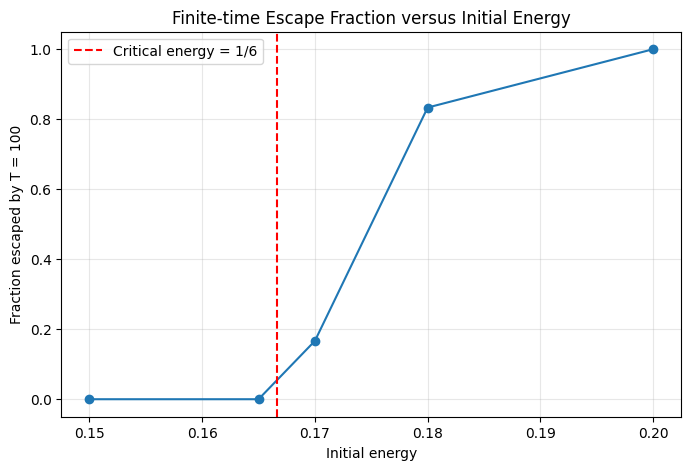

In [58]:
energy_escape_fractions = [result["escape_fraction"] for result in energy_results]

plt.figure(figsize=(8, 5))
plt.plot(energy_values, energy_escape_fractions, "o-")
plt.axvline(1/6, color="red", linestyle="--", label="Critical energy = 1/6")
plt.xlabel("Initial energy")
plt.ylabel("Fraction escaped by T = 100")
plt.title("Finite-time Escape Fraction versus Initial Energy")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 17. Refined energy scan near the escape threshold

**What this section does:** Repeats the energy study above threshold with $5^\circ$ angular spacing (72 launch directions per energy). The escape fraction is measured only up to $T=100$, so it is a time bound, spacing dependent fraction.

**README:** [Energy parameter study](README.md#energy-parameter-study).

In [59]:
fine_energy_values = [0.167, 0.170, 0.175, 0.18, 0.20]
fine_energy_scan_N = 20000
fine_energy_scan_step = 5
fine_energy_results = []

for energy_value in fine_energy_values:
    energy_info = escape_statistics(T, fine_energy_scan_N, energy_value, R, 0, 360, fine_energy_scan_step)
    escaped = [entry for entry in energy_info if entry["escaped"]]
    counts = {"Upper": 0, "Lower-left": 0, "Lower-right": 0, "Unclassified": 0}

    for entry in escaped:
        counts[entry["channel"]] += 1

    fraction = len(escaped) / len(energy_info)
    fine_energy_results.append({"energy": energy_value,
                                "total": len(energy_info),
                                "escaped": len(escaped),
                                "not_escaped": len(energy_info) - len(escaped),
                                "escape_fraction": fraction,
                                "channel_counts": counts})
    print("E =", energy_value, "| Escaped:", len(escaped), "| Not escaped:", len(energy_info) - len(escaped), "| Fraction:", fraction)

print("Critical energy:", 1/6, "| Angular step:", fine_energy_scan_step, "| N:", fine_energy_scan_N, "| T:", T)

E = 0.167 | Escaped: 6 | Not escaped: 66 | Fraction: 0.08333333333333333
E = 0.17 | Escaped: 18 | Not escaped: 54 | Fraction: 0.25
E = 0.175 | Escaped: 24 | Not escaped: 48 | Fraction: 0.3333333333333333
E = 0.18 | Escaped: 54 | Not escaped: 18 | Fraction: 0.75
E = 0.2 | Escaped: 72 | Not escaped: 0 | Fraction: 1.0
Critical energy: 0.16666666666666666 | Angular step: 5 | N: 20000 | T: 100


### Finite-time escape fraction for the refined energy scan

**What this plot shows:** The measured fraction of the 72 sampled launch directions that escape by $T=100$, plotted against initial energy. The vertical line marks $E_c=1/6$.

**README:** [Energy parameter study](README.md#energy-parameter-study).

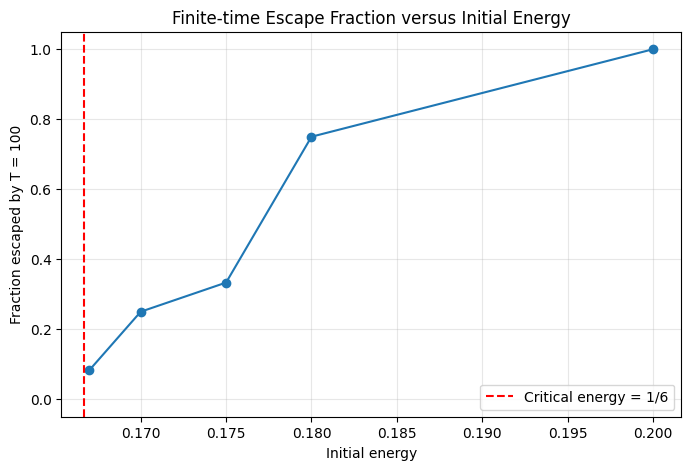

In [60]:
fine_escape_fractions = [result["escape_fraction"] for result in fine_energy_results]

plt.figure(figsize=(8, 5))
plt.plot(fine_energy_values, fine_escape_fractions, "o-")
plt.axvline(1/6, color="red", linestyle="--", label="Critical energy = 1/6")
plt.xlabel("Initial energy")
plt.ylabel("Fraction escaped by T = 100")
plt.title("Finite-time Escape Fraction versus Initial Energy")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 18. Fine angular basin scans

**What this section does:** Repeats the $22^\circ$–$23^\circ$ angular scan at $0.01^\circ$ spacing for $N=20{,}000$ and $N=40{,}000$. Comparing the two resolutions tests how sensitive the observed escape basin is to the integration timestep.

**README:** [Escape-basin investigation](README.md#escape-basin-investigation) and [limitations](README.md#limitations).

In [61]:
res_fine = 0.01
info_fine_20000 = escape_statistics(T, 20000, E, R, 22, 23, res_fine)
transitions_fine_20000 = return_transitions(info_fine_20000, circular=False)

print("Number of sampled angles:", len(info_fine_20000))
print("Transitions at N=20000:", len(transitions_fine_20000))

Number of sampled angles: 100
Transitions at N=20000: 37


In [62]:
info_fine_40000 = escape_statistics(T, 40000, E, R, 22, 23, res_fine)
transitions_fine_40000 = return_transitions(info_fine_40000, circular=False)

print("Number of sampled angles:", len(info_fine_40000))
print("Transitions at N=40000:", len(transitions_fine_40000))

Number of sampled angles: 100
Transitions at N=40000: 50


## 19. Comparing basin outcomes across resolutions

**What this section does:** Counts how many of the 100 sampled angles change outcome when the integration step is halved, then plots both outcome maps for direct comparison.

**README:** [Escape-basin investigation](README.md#escape-basin-investigation).

Changed outcomes: 31
Fraction changed: 0.31


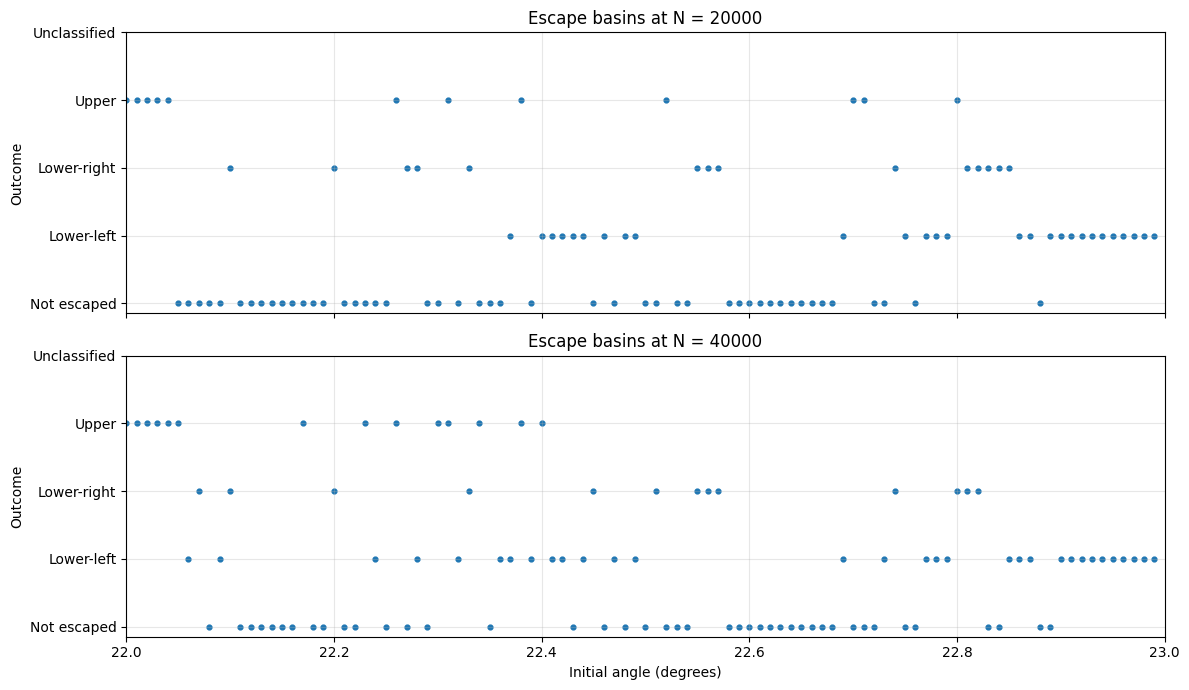

In [63]:
def entry_outcome(entry):
    return entry["channel"] if entry["escaped"] else "Not escaped by T"

changed = sum(entry_outcome(a) != entry_outcome(b) for a, b in zip(info_fine_20000, info_fine_40000))
print("Changed outcomes:", changed)
print("Fraction changed:", changed/len(info_fine_20000))

outcome_codes = {"Not escaped by T": -1, "Lower-left": 0, "Lower-right": 1, "Upper": 2, "Unclassified": 3}
fine_angles = [entry["theta"] for entry in info_fine_20000]
outcomes_20000 = [outcome_codes[entry_outcome(entry)] for entry in info_fine_20000]
outcomes_40000 = [outcome_codes[entry_outcome(entry)] for entry in info_fine_40000]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, outcomes, n in zip(axes, [outcomes_20000, outcomes_40000], [20000, 40000]):
    ax.scatter(fine_angles, outcomes, s=12)
    ax.set_yticks([-1, 0, 1, 2, 3])
    ax.set_yticklabels(["Not escaped", "Lower-left", "Lower-right", "Upper", "Unclassified"])
    ax.set_ylabel("Outcome")
    ax.set_title("Escape basins at N = " + str(n))
    ax.grid(alpha=0.3)

axes[1].set_xlabel("Initial angle (degrees)")
plt.xlim(22, 23)
plt.tight_layout()
plt.show()

## 20. Uncertainty fraction and angular scale

**What this section does:** For several angular separations, calculates the fraction of sampled pairs with different outcomes at both integration resolutions. This is a diagnostic of scale-dependent basin complexity, not a fractal-dimension fit or proof of fractality.

**README:** [Limitations and future work](README.md#limitations).

delta: 0.01 | N=20000: 0.37373737373737376 | N=40000: 0.5050505050505051
delta: 0.02 | N=20000: 0.45918367346938777 | N=40000: 0.5510204081632653
delta: 0.03 | N=20000: 0.4948453608247423 | N=40000: 0.5773195876288659
delta: 0.05 | N=20000: 0.5578947368421052 | N=40000: 0.5684210526315789
delta: 0.08 | N=20000: 0.5869565217391305 | N=40000: 0.5543478260869565
delta: 0.1 | N=20000: 0.6333333333333333 | N=40000: 0.6777777777777778
delta: 0.15 | N=20000: 0.6823529411764706 | N=40000: 0.7647058823529411
delta: 0.2 | N=20000: 0.7375 | N=40000: 0.8
delta: 0.3 | N=20000: 0.7 | N=40000: 0.7
delta: 0.4 | N=20000: 0.7 | N=40000: 0.7
delta: 0.5 | N=20000: 0.54 | N=40000: 0.6


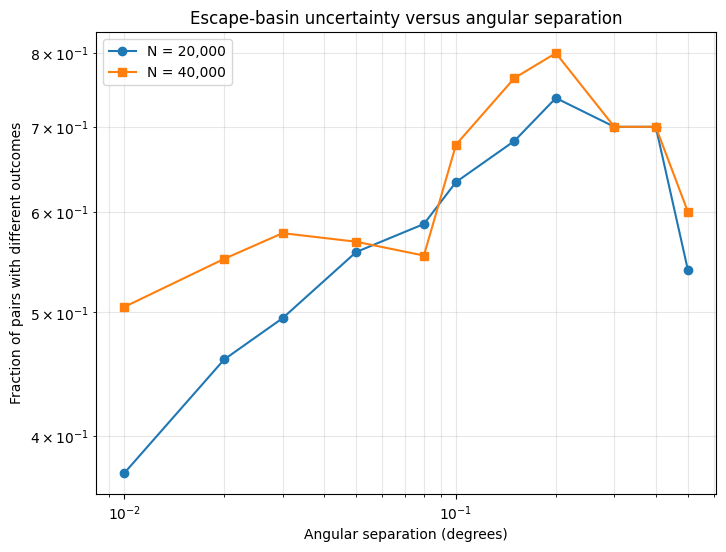

In [64]:
m_values = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50]
delta_values = []
fraction_20000 = []
fraction_40000 = []

for m in m_values:
    total = len(info_fine_20000) - m
    different_20000 = 0
    different_40000 = 0

    for i in range(total):
        if entry_outcome(info_fine_20000[i]) != entry_outcome(info_fine_20000[i+m]):
            different_20000 += 1
        if entry_outcome(info_fine_40000[i]) != entry_outcome(info_fine_40000[i+m]):
            different_40000 += 1

    delta_values.append(m*res_fine)
    fraction_20000.append(different_20000/total)
    fraction_40000.append(different_40000/total)

    print("delta:", m*res_fine, "| N=20000:", different_20000/total, "| N=40000:", different_40000/total)

plt.figure(figsize=(8, 6))
plt.loglog(delta_values, fraction_20000, "o-", label="N = 20,000")
plt.loglog(delta_values, fraction_40000, "s-", label="N = 40,000")
plt.xlabel("Angular separation (degrees)")
plt.ylabel("Fraction of pairs with different outcomes")
plt.title("Escape-basin uncertainty versus angular separation")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()